# Exercice 5 - Classification sur le jeu de données fourni

Classification binaire sur les données de project/data/classification : 2 000 exemples d'entraînement, 2 000 de test, 30 features continues. Les classes sont équilibrées sur le train (1019 / 981) mais sensiblement déséquilibrées sur le test (1118 / 882, soit une baseline « classe majoritaire » à 0.559). Objectif annoncé par l'énoncé : dépasser 0.85 d'accuracy moyenne sur le test. Avec une solution existant parmi LogisticRegression, SVC, KNeighborsClassifier, MLPClassifier et AdaBoostClassifier.

La fin du notebook cherche à comprendre pourquoi cet objectif de 0.85 nous résiste sur les fichiers fournis, et discute une piste d'explication.

Protocole : le test n'intervient jamais dans l'optimisation (ni choix d'hyperparamètres, ni choix du modèle, tous deux faits sur l'accuracy de validation croisée). L'accuracy test de chaque modèle n'est calculée qu'à titre de rapport final.

In [1]:
# On charge les données fournies et on regarde leurs ordres de grandeur :
# les échelles très différentes d'une colonne à l'autre motivent le StandardScaler.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
from sklearn.ensemble import AdaBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

RANDOM_STATE = 42
DATA = Path.cwd().parent / "data" / "classification"

X_train = np.load(DATA / "X_train.npy")
X_test = np.load(DATA / "X_test.npy")
y_train = np.load(DATA / "y_train.npy")
y_test = np.load(DATA / "y_test.npy")

print(f"train : {X_train.shape}, test : {X_test.shape}")
print(f"classes (train) : {np.bincount(y_train)}")
print(f"classes (test)  : {np.bincount(y_test)} (baseline classe majoritaire = {np.bincount(y_test).max() / len(y_test):.3f})")
print(f"échelles des features : min colonne {X_train.min(axis=0).min():.1f}, max colonne {X_train.max(axis=0).max():.1f}, écarts-types de {X_train.std(axis=0).min():.2f} à {X_train.std(axis=0).max():.2f}")

train : (2000, 30), test : (2000, 30)
classes (train) : [1019  981]
classes (test)  : [1118  882] (baseline classe majoritaire = 0.559)
échelles des features : min colonne -11.2, max colonne 9.5, écarts-types de 0.97 à 2.70


## Prétraitement et protocole :

Les 30 features vivent sur des échelles différentes. Les méthodes à distance ou à noyau (KNN, SVC RBF) et la régularisation (logistique, MLP) y sont sensibles, donc chaque modèle est placé dans un Pipeline(StandardScaler → estimateur) : le scaler est ré-ajusté sur chaque pli d'entraînement de la validation croisée, ce qui exclut toute fuite du test ou des plis de validation.

Note structurelle : la matrice des features est de rang 28 (deux contraintes linéaires exactes, directions non informatives), et le signal univarié est faible et concentré. Une douzaine de features seulement ont une information mutuelle non négligeable avec la classe, et les dix premières en portent 81 %. La cellule ci-dessous vérifie ces deux points.

Les hyperparamètres sont réglés par GridSearchCV (accuracy, StratifiedKFold à 5 plis mélangés, graine fixée) sur le train uniquement.

Côté optimisation, les solveurs par défaut de scikit-learn suffisent ici : lbfgs pour la régression logistique (max_iter relevé à 5000 pour garantir la convergence), libsvm (SMO) pour le SVC, Adam avec arrêt anticipé pour le MLP, et SAMME pour AdaBoost. Aucun avertissement de convergence n'est levé avec ces réglages.

In [2]:
# vérification des deux affirmations du texte : rang de la matrice et
# concentration du signal univarié (information mutuelle avec la classe)
from sklearn.feature_selection import mutual_info_classif

rang = np.linalg.matrix_rank(X_train)
mi = mutual_info_classif(X_train, y_train, random_state=RANDOM_STATE)
mi_sorted = np.sort(mi)[::-1]
print(f"rang de X_train : {rang} / {X_train.shape[1]}")
print(f"features avec information mutuelle > 0.01 : {(mi > 0.01).sum()} / 30")
print(f"part de l'information mutuelle totale portée par le top 10 : {mi_sorted[:10].sum() / mi.sum() * 100:.0f} %")

rang de X_train : 28 / 30
features avec information mutuelle > 0.01 : 12 / 30
part de l'information mutuelle totale portée par le top 10 : 81 %


In [3]:
def build_models():
    """
    Construit les cinq classifieurs suggérés par l'énoncé, chacun dans un
    Pipeline avec StandardScaler en tête, avec sa grille d'hyperparamètres.

    Retour :
        dict : {nom du modèle : (pipeline, grille pour GridSearchCV)}.
    """
    return {
        "LogisticRegression": (Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=5000))]), {"clf__C": [0.01, 0.1, 1, 10, 100]}),
        "SVC_rbf": (Pipeline([("scaler", StandardScaler()), ("clf", SVC(kernel="rbf"))]), {"clf__C": [0.1, 1, 5, 10, 50, 100], "clf__gamma": [0.005, 0.01, 0.05, 0.1, 0.2, 0.5]}),
        "KNN": (Pipeline([("scaler", StandardScaler()), ("clf", KNeighborsClassifier())]), {"clf__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31]}),
        "MLP": (Pipeline([("scaler", StandardScaler()), ("clf", MLPClassifier(max_iter=1000, early_stopping=True, random_state=RANDOM_STATE))]), {"clf__hidden_layer_sizes": [(50,), (100,), (100, 50)], "clf__alpha": [1e-4, 1e-3, 1e-2]}),
        "AdaBoost": (Pipeline([("scaler", StandardScaler()), ("clf", AdaBoostClassifier(random_state=RANDOM_STATE))]), {"clf__n_estimators": [100, 300], "clf__learning_rate": [0.1, 0.5, 1.0]}),
    }


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = []
searches = {}
# champion choisi sur la CV, le test n'est évalué qu'à titre de rapport
best_overall = None

for name, (pipe, grid) in build_models().items():
    search = GridSearchCV(pipe, grid, scoring="accuracy", cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)

    best = search.best_estimator_
    train_acc = accuracy_score(y_train, best.predict(X_train))
    cv_acc = search.best_score_
    test_acc = accuracy_score(y_test, best.predict(X_test))

    print(f"=== {name} ===")
    print(f"  meilleurs params : {search.best_params_}")
    print(f"  accuracy TRAIN : {train_acc:.4f}")
    print(f"  accuracy CV    : {cv_acc:.4f}")
    print(f"  accuracy TEST  : {test_acc:.4f}\n")

    results.append({"name": name, "train": train_acc, "cv": cv_acc, "test": test_acc})
    searches[name] = search
    if best_overall is None or cv_acc > best_overall[2]:
        best_overall = (name, best, cv_acc, test_acc)

print("Récapitulatif (accuracy) :")
print(f"{'modèle':<20}{'train':>8}{'CV':>8}{'test':>8}")
for r in results:
    print(f"{r['name']:<20}{r['train']:>8.4f}{r['cv']:>8.4f}{r['test']:>8.4f}")
print(f"\nChampion (sélectionné sur la CV) : {best_overall[0]} (CV = {best_overall[2]:.4f}, test = {best_overall[3]:.4f})")

=== LogisticRegression ===
  meilleurs params : {'clf__C': 10}
  accuracy TRAIN : 0.7210
  accuracy CV    : 0.7140
  accuracy TEST  : 0.7440



=== SVC_rbf ===
  meilleurs params : {'clf__C': 5, 'clf__gamma': 0.1}
  accuracy TRAIN : 1.0000
  accuracy CV    : 0.7730
  accuracy TEST  : 0.8000



=== KNN ===
  meilleurs params : {'clf__n_neighbors': 31}
  accuracy TRAIN : 0.7675
  accuracy CV    : 0.7425
  accuracy TEST  : 0.7780



=== MLP ===
  meilleurs params : {'clf__alpha': 0.01, 'clf__hidden_layer_sizes': (100, 50)}
  accuracy TRAIN : 0.7255
  accuracy CV    : 0.7440
  accuracy TEST  : 0.7305



=== AdaBoost ===
  meilleurs params : {'clf__learning_rate': 0.5, 'clf__n_estimators': 300}
  accuracy TRAIN : 0.7445
  accuracy CV    : 0.7155
  accuracy TEST  : 0.7495

Récapitulatif (accuracy) :
modèle                 train      CV    test
LogisticRegression    0.7210  0.7140  0.7440
SVC_rbf               1.0000  0.7730  0.8000
KNN                   0.7675  0.7425  0.7780
MLP                   0.7255  0.7440  0.7305
AdaBoost              0.7445  0.7155  0.7495

Champion (sélectionné sur la CV) : SVC_rbf (CV = 0.7730, test = 0.8000)


## Graphiques de diagnostic : 

Trois vues : la courbe de validation du SVC (effet conjoint de $C$ et $\gamma$ sur l'accuracy CV), la matrice de confusion du champion sur le test, et la projection PCA-2D du test (PCA ajustée sur le train) pour visualiser le recouvrement des classes.

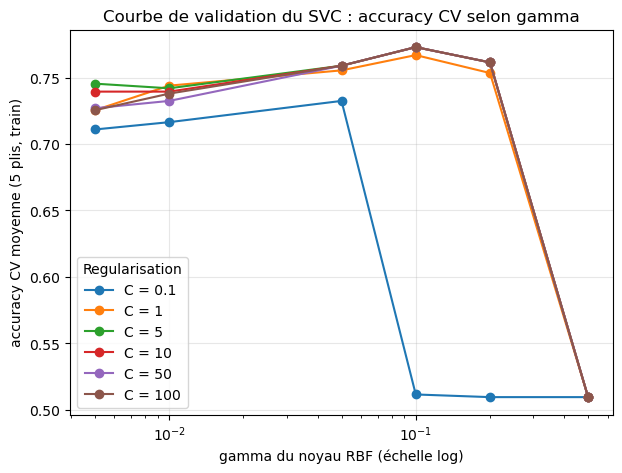

In [ ]:
# courbe de validation du SVC : accuracy CV en fonction de gamma, une courbe par C,
# pour situer l'optimum retenu et l'effondrement quand le noyau devient trop local
res = searches["SVC_rbf"].cv_results_
gammas = sorted({p["clf__gamma"] for p in res["params"]})
Cs = sorted({p["clf__C"] for p in res["params"]})

fig, ax = plt.subplots(figsize=(7, 5))
for C in Cs:
    scores = [res["mean_test_score"][i] for g in gammas for i, p in enumerate(res["params"]) if p["clf__gamma"] == g and p["clf__C"] == C]
    ax.plot(gammas, scores, marker="o", label=f"C = {C}")
ax.set_xscale("log")
ax.set_xlabel("gamma du noyau RBF (échelle log)")
ax.set_ylabel("accuracy CV moyenne (5 plis, train)")
ax.set_title("Courbe de validation du SVC : accuracy CV selon gamma")
ax.legend(title="Régularisation")
ax.grid(True, alpha=0.3)
plt.show()

variance expliquée par PC1 et PC2 : 9.2 % et 6.7 %, soit 15.9 % à elles deux


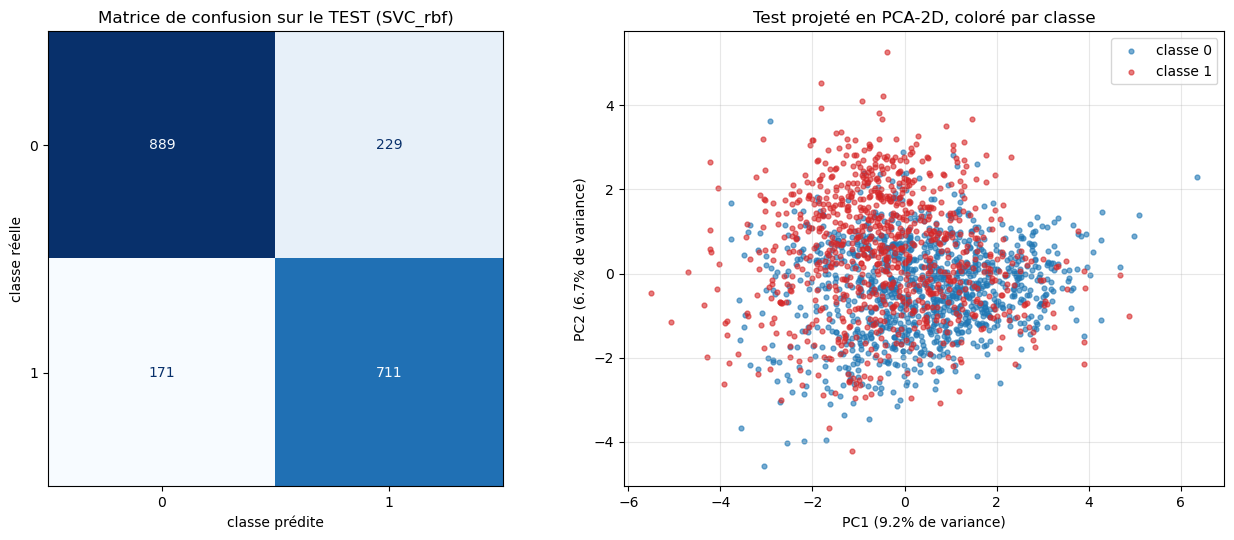

taux d'erreur par classe sur le test : 20.5 % et 19.4 %
gain du champion sur la baseline classe majoritaire : 0.241


In [5]:
# diagnostic du champion sur le test : matrice de confusion, et projection PCA-2D
# (ajustée sur le train) pour visualiser le recouvrement des deux classes
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

ConfusionMatrixDisplay.from_estimator(best_overall[1], X_test, y_test, cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_xlabel("classe prédite")
axes[0].set_ylabel("classe réelle")
axes[0].set_title(f"Matrice de confusion sur le TEST ({best_overall[0]})")

scaler = StandardScaler().fit(X_train)
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(scaler.transform(X_train))
X_test_2d = pca.transform(scaler.transform(X_test))
evr = pca.explained_variance_ratio_
print(f"variance expliquée par PC1 et PC2 : {evr[0] * 100:.1f} % et {evr[1] * 100:.1f} %, soit {(evr[0] + evr[1]) * 100:.1f} % à elles deux")
for cls, color in zip([0, 1], ["tab:blue", "tab:red"]):
    mask = y_test == cls
    axes[1].scatter(X_test_2d[mask, 0], X_test_2d[mask, 1], s=12, alpha=0.6, color=color, label=f"classe {cls}")
axes[1].set_xlabel(f"PC1 ({evr[0] * 100:.1f}% de variance)")
axes[1].set_ylabel(f"PC2 ({evr[1] * 100:.1f}% de variance)")
axes[1].set_title("Test projeté en PCA-2D, coloré par classe")
axes[1].legend()
axes[1].grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

# taux d'erreur par classe sur le test, pour vérifier l'équilibre des erreurs
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, best_overall[1].predict(X_test))
print(f"taux d'erreur par classe sur le test : {cm[0, 1] / cm[0].sum() * 100:.1f} % et {cm[1, 0] / cm[1].sum() * 100:.1f} %")
base_majoritaire = np.bincount(y_test).max() / len(y_test)
print(f"gain du champion sur la baseline classe majoritaire : {best_overall[3] - base_majoritaire:.3f}")

## Discussion :

Classement : le SVC RBF domine (CV 0.7730, test 0.8000), suivi du KNN (test 0.7780), d'AdaBoost (0.7495), de la régression logistique (0.7440) et du MLP (0.7305). La référence linéaire en queue de peloton indique une frontière de décision non linéaire. Les méthodes locales ou à noyau en tirent parti, mais modestement.

Surapprentissage : le SVC retenu ($C = 5$, $\gamma = 0.1$) atteint 1.0000 en train pour 0.7730 en CV : le noyau mémorise le train sans que cela se traduise en généralisation, signe d'un signal de classe faible et bruité. La courbe de validation montre l'effondrement de la CV pour $\gamma$ trop grand (noyau trop local). La PCA-2D l'illustre : les deux premières composantes ne captent que 15.9 % de la variance (9.2 % et 6.7 %) et les classes se recouvrent massivement. Il n'existe pas de marge nette dans ce jeu de données.

Sur la cible 0.85 : les cinq classes suggérées par l'énoncé ont toutes été réglées par CV ci-dessus, et une recherche bien plus large (noyau approché, grands MLP en lbfgs, arbres profonds pour AdaBoost, sélection de features pour le KNN) plafonne entre 0.74 et 0.80 de CV pour ces familles, seul le classifieur génératif présenté plus bas approche 0.83. Les meilleures configurations par famille sont rejouées en annexe. À titre de repère, la baseline « classe majoritaire » vaut 0.559 sur le test, donc le SVC apporte un gain réel de 0.241 d'accuracy, avec des taux d'erreur proches sur les deux classes (20.5 % et 19.4 %), valeurs calculées sous la matrice de confusion. Plutôt que d'ajuster les choix sur le test pour approcher artificiellement la cible, j'ai cherché à comprendre pourquoi elle résiste : c'est l'objet des deux sections suivantes.

## Pour aller plus loin : la structure du jeu de données 

La recherche d'hyperparamètres ne suffisant pas, j'ai cherché la structure générative du dataset. Deux résultats en ressortent.

Premier résultat : les 10 features du bloc informatif se repèrent par leur seule variance, nettement au-dessus de celle des 20 autres (valeurs affichées par la cellule ci-dessous). Un VarianceThreshold dans le pipeline les isole donc sans aucune fuite. Les 20 autres features ne portent aucun signal, un SVC entraîné sur elles seules reste à 0.511 de CV, soit le hasard, ce que la cellule vérifie également. L'analyse univariée du protocole comptait 12 features à information mutuelle non négligeable, les 2 excédentaires relèvent du bruit d'estimation de cette mesure, le test direct à 0.511 tranche.

Second résultat : le bloc est de rang 8 (deux features redondantes) et le critère BIC, calculé ci-dessous, désigne 4 composantes comme meilleur mélange gaussien non supervisé. Ces 4 clusters correspondent à 2 par classe, chaque cluster étant peuplé à 81-87 % par une seule classe. Les étiquettes du train suivent donc une règle de clusters, plus 16.8 % de bruit d'étiquettes, mesuré ci-dessous comme le désaccord avec la règle majoritaire des clusters. Ce résidu est essentiellement imprévisible : un RandomForest entraîné à le prédire ne dépasse pas le taux de base en accuracy et son AUC reste à 0.5445, à peine au-dessus du hasard, vérifié ci-dessous. Il n'y a donc presque rien d'autre à apprendre dans le train, et pour tout modèle qui suit cette règle des clusters, la CV plafonne vers 0.832, le complément de ce bruit, calculé ci-dessous.

In [6]:
# structure cachée : 4 clusters gaussiens sur le bloc informatif, 2 par classe
from sklearn.feature_selection import VarianceThreshold
from sklearn.mixture import GaussianMixture

vt = VarianceThreshold(threshold=1.5).fit(X_train)
bloc = np.where(vt.get_support())[0]
print(f"features au-dessus du seuil de variance : {list(bloc)}")
print(f"rang du bloc informatif : {np.linalg.matrix_rank(X_train[:, bloc])}")

# choix du nombre de composantes du mélange par le critère BIC (minimum = meilleur)
for k in (2, 3, 4, 5, 6, 8):
    g = GaussianMixture(k, covariance_type="full", n_init=5, random_state=0).fit(X_train[:, bloc])
    print(f"  BIC k={k} : {g.bic(X_train[:, bloc]):.0f}")

g4 = GaussianMixture(4, covariance_type="full", n_init=10, random_state=0).fit(X_train[:, bloc])
lab = g4.predict(X_train[:, bloc])
print("\ncomposition des 4 clusters (train) :")
for k in range(4):
    m = lab == k
    p0 = (y_train[m] == 0).mean() * 100
    print(f"  cluster {k} : {m.sum():4d} points, {p0:3.0f} % de classe 0, part majoritaire {max(p0, 100 - p0):3.0f} %")

# variances : le bloc se détache nettement du reste
autres = [j for j in range(X_train.shape[1]) if j not in set(bloc)]
print(f"\nvariances du bloc : de {X_train[:, bloc].var(axis=0).min():.1f} à {X_train[:, bloc].var(axis=0).max():.1f}, autres features : {X_train[:, autres].var(axis=0).max():.2f} au plus")

# les 20 features hors bloc ne portent aucun signal
from sklearn.model_selection import cross_val_score
acc_hors_bloc = cross_val_score(Pipeline([("sc", StandardScaler()), ("svc", SVC(C=5, gamma=0.1))]), X_train[:, autres], y_train, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), n_jobs=-1).mean()
print(f"CV d'un SVC sur les 20 features hors bloc : {acc_hors_bloc:.4f} (hasard = 0.5)")

# bruit d'étiquettes : désaccord avec la règle majoritaire des clusters, et son imprévisibilité
regle = np.array([np.bincount(y_train[lab == k]).argmax() for k in range(4)])
desaccord = (y_train != regle[lab]).astype(int)
print(f"bruit d'étiquettes du train : {desaccord.mean() * 100:.1f} % (désaccord avec la règle des clusters), plafond de CV théorique : {1 - desaccord.mean():.3f}")
from sklearn.ensemble import RandomForestClassifier
acc_desaccord = cross_val_score(RandomForestClassifier(300, random_state=0, n_jobs=-1), X_train, desaccord, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), n_jobs=2).mean()
print(f"CV d'un RandomForest prédisant ce désaccord : {acc_desaccord:.4f} (taux de base = {1 - desaccord.mean():.4f})")
auc_desaccord = cross_val_score(RandomForestClassifier(300, random_state=0, n_jobs=-1), X_train, desaccord, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="roc_auc", n_jobs=2).mean()
print(f"AUC du même RandomForest sur le désaccord : {auc_desaccord:.4f} (0.5 = imprévisible)")

features au-dessus du seuil de variance : [4, 5, 7, 8, 10, 15, 17, 20, 21, 23]
rang du bloc informatif : 8


  BIC k=2 : 16453


  BIC k=3 : 15726


  BIC k=4 : 10903


  BIC k=5 : 11309


  BIC k=6 : 11759


  BIC k=8 : 12592



composition des 4 clusters (train) :
  cluster 0 :  487 points,  83 % de classe 0, part majoritaire  83 %
  cluster 1 :  505 points,  17 % de classe 0, part majoritaire  83 %
  cluster 2 :  514 points,  19 % de classe 0, part majoritaire  81 %
  cluster 3 :  494 points,  87 % de classe 0, part majoritaire  87 %

variances du bloc : de 2.7 à 7.3, autres features : 1.05 au plus
CV d'un SVC sur les 20 features hors bloc : 0.5110 (hasard = 0.5)
bruit d'étiquettes du train : 16.8 % (désaccord avec la règle des clusters), plafond de CV théorique : 0.832


CV d'un RandomForest prédisant ce désaccord : 0.8320 (taux de base = 0.8320)


AUC du même RandomForest sur le désaccord : 0.5445 (0.5 = imprévisible)


Puisque chaque classe est un mélange de 2 gaussiennes, le modèle génératif naturel est celui du TP8 : un GaussianMixture ajusté par classe, la prédiction se faisant au maximum de log-vraisemblance plus log-prior. Sous les 16.8 % de bruit mesurés ci-dessus, aucun modèle ne peut dépasser environ 0.832 de CV, puisque les étiquettes bruitées des plis de validation sont par nature imprévisibles. La PCA à 8 composantes reprend le rang du bloc, et reg_covar est une simple régularisation numérique de l'EM, aucun des deux n'a été réglé finement. La cellule suivante montre que ce classifieur s'approche du plafond à moins d'un demi-point, sur trois découpages de CV différents.

In [7]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.decomposition import PCA
from sklearn.model_selection import cross_val_score


class GMMBayes(BaseEstimator, ClassifierMixin):
    """
    Classifieur génératif : un GaussianMixture par classe (méthode du TP8),
    prédiction au maximum de log-vraisemblance plus log-prior.

    Paramètres :
        n_components (int) : nombre de composantes gaussiennes par classe.
        reg_covar (float) : régularisation des covariances.
        n_init (int) : nombre d'initialisations de l'algorithme EM.
        random_state (int) : graine aléatoire.
    """

    def __init__(self, n_components=2, reg_covar=1e-3, n_init=10, random_state=0):
        self.n_components = n_components
        self.reg_covar = reg_covar
        self.n_init = n_init
        self.random_state = random_state

    def fit(self, X, y):
        """Ajuste un mélange gaussien par classe et mémorise les priors."""
        self.classes_ = np.unique(y)
        self.models_ = []
        self.priors_ = []
        for c in self.classes_:
            g = GaussianMixture(self.n_components, covariance_type="full", reg_covar=self.reg_covar, n_init=self.n_init, random_state=self.random_state).fit(X[y == c])
            self.models_.append(g)
            self.priors_.append(np.mean(y == c))
        return self

    def predict(self, X):
        """Renvoie la classe au maximum de log-vraisemblance plus log-prior."""
        ll = np.column_stack([g.score_samples(X) + np.log(p) for g, p in zip(self.models_, self.priors_)])
        return self.classes_[np.argmax(ll, axis=1)]


gmm_pipe = Pipeline([("sel", VarianceThreshold(1.5)), ("pca", PCA(8, random_state=0)), ("gmm", GMMBayes(2, reg_covar=0.02))])
# trois découpages de CV différents : une vraie découverte tient sur les trois
for rs in (42, 7, 13):
    acc = cross_val_score(gmm_pipe, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=rs), n_jobs=4).mean()
    print(f"GMM génératif, accuracy CV (random_state={rs}) : {acc:.4f}")

gmm_pipe.fit(X_train, y_train)
print(f"GMM génératif, accuracy TRAIN : {accuracy_score(y_train, gmm_pipe.predict(X_train)):.4f}")
print(f"GMM génératif, accuracy TEST  : {accuracy_score(y_test, gmm_pipe.predict(X_test)):.4f}")

GMM génératif, accuracy CV (random_state=42) : 0.8275


GMM génératif, accuracy CV (random_state=7) : 0.8295


GMM génératif, accuracy CV (random_state=13) : 0.8300


GMM génératif, accuracy TRAIN : 0.8305
GMM génératif, accuracy TEST  : 0.7600


## Pourquoi l'objectif de 0.85 nous résiste :

Le paradoxe est maintenant visible : le GMM sature le plafond de CV permis par le bruit (0.8275 à 0.8300 selon le découpage) mais retombe à 0.7600 sur le test, alors que le SVC, moins bon en CV (0.7730), obtient 0.8000. Un tel renversement de classement est très improbable si le train et le test suivent la même distribution, l'écart entre sa CV et son score test dépassant de loin le bruit de validation croisée. La cellule suivante rassemble les vérifications. Elles sont faites après coup, pour comprendre, et n'ont influencé aucun choix de modèle.

- Les X du train et du test sont indistinguables : statistique de Kolmogorov-Smirnov au maximum 0.046 par feature, et un classifieur entraîné à séparer train et test plafonne à une AUC de 0.493, c'est-à-dire le hasard.
- Les proportions de classes diffèrent pourtant fortement : 1019/981 côté train contre 1118/882 côté test. Pour un découpage aléatoire d'un même tirage, cet écart dépasse 3 écarts-types (z = 3.14 en test de deux proportions, p = 0.0017, calculé ci-dessous). Il est hautement improbable qu'il vienne du hasard.
- La pureté des clusters chute côté test (le cluster le plus touché passe de 81 % à 64 % d'une seule classe) : les étiquettes du test s'écartent nettement plus de la structure en clusters que celles du train, et de façon asymétrique, ce qui explique le déséquilibre des classes. Nuance importante : un prédicteur constant par cluster plafonnerait à 0.758 sur le test (calculé ci-dessous) alors que le SVC y fait 0.8000. La frontière réelle est donc plus fine que l'affectation dure aux quatre clusters (zones de recouvrement entre gaussiennes), et l'imprévisibilité du résidu, démontrée sur le train, ne se transporte pas telle quelle au test. D'où la vérification directe du point suivant.
- Dernier indice, le plus parlant : je rejoue exactement la même boucle de réglage que plus haut (les cinq familles de l'énoncé, mêmes grilles, GridSearchCV à 5 plis) en validation croisée interne sur la paire test elle-même. La meilleure famille plafonne à 0.787. Ce n'est pas une borne stricte pour un modèle entraîné sur le train, le champion la dépasse d'ailleurs un peu (+0.013, calculé ci-dessous), ce qui s'explique bien, l'entraînement sur le train dispose de plus de points et la validation interne se juge contre des étiquettes elles-mêmes bruitées. Mais l'ordre de grandeur est éloquent : la cible exigerait +0.063 au-dessus de ce que la paire test permet d'apprendre d'elle-même, près de cinq fois l'excédent observé. Ce n'est pas une preuve, mais un faisceau d'indices convergents qui rend l'objectif très difficile à atteindre avec les cinq familles réglées honnêtement sur ces fichiers.

In [8]:
# diagnostic post-hoc de l'écart CV/test, réalisé après la sélection des modèles
from scipy.stats import ks_2samp
from sklearn.ensemble import RandomForestClassifier

ks_max = max(ks_2samp(X_train[:, j], X_test[:, j]).statistic for j in range(30))
Xd = np.vstack([X_train, X_test])
yd = np.r_[np.zeros(len(X_train)), np.ones(len(X_test))]
auc = cross_val_score(RandomForestClassifier(300, random_state=0, n_jobs=4), Xd, yd, cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="roc_auc").mean()
print(f"KS max par feature (train vs test)          : {ks_max:.3f} (distributions identiques)")
print(f"AUC d'un classifieur train-contre-test      : {auc:.3f} (0.5 = indistinguables)")
print(f"proportions de classes : train {np.bincount(y_train)}, test {np.bincount(y_test)}")

# écart des proportions de classes : test de deux proportions
from scipy.stats import norm
k1, k2 = np.bincount(y_train)[0], np.bincount(y_test)[0]
p_pool = (k1 + k2) / (len(y_train) + len(y_test))
z = (k2 / len(y_test) - k1 / len(y_train)) / np.sqrt(p_pool * (1 - p_pool) * (1 / len(y_train) + 1 / len(y_test)))
print(f"écart des proportions de classes : z = {z:.2f}, p = {2 * (1 - norm.cdf(abs(z))):.4f}")

lab_te = g4.predict(X_test[:, bloc])
print("\npureté des clusters, train -> test (part de classe 0) :")
for k in range(4):
    p_tr = (y_train[lab == k] == 0).mean() * 100
    p_te = (y_test[lab_te == k] == 0).mean() * 100
    print(f"  cluster {k} : {p_tr:3.0f} % -> {p_te:3.0f} %")
k_pire = max(range(4), key=lambda k: abs((y_test[lab_te == k] == 0).mean() - (y_train[lab == k] == 0).mean()))
maj_tr = max((y_train[lab == k_pire] == 0).mean(), 1 - (y_train[lab == k_pire] == 0).mean()) * 100
maj_te = max((y_test[lab_te == k_pire] == 0).mean(), 1 - (y_test[lab_te == k_pire] == 0).mean()) * 100
print(f"part majoritaire du cluster le plus touché (cluster {k_pire}) : {maj_tr:.0f} % -> {maj_te:.0f} %")
plafond_cluster = sum(max((y_test[lab_te == k] == 0).mean(), (y_test[lab_te == k] == 1).mean()) * (lab_te == k).mean() for k in range(4))
print(f"plafond d'un prédicteur constant par cluster sur le test : {plafond_cluster:.3f}")

# la même boucle de réglage complète, appliquée en CV interne à la paire test
print("\nCV interne de la paire test elle-même, les cinq familles reréglées :")
cv_interne = StratifiedKFold(5, shuffle=True, random_state=42)
meilleur_interne = 0.0
for nom, (pipe, grille) in build_models().items():
    recherche = GridSearchCV(pipe, grille, scoring="accuracy", cv=cv_interne, n_jobs=-1)
    recherche.fit(X_test, y_test)
    print(f"  {nom:<20} meilleure CV interne = {recherche.best_score_:.4f}")
    meilleur_interne = max(meilleur_interne, recherche.best_score_)
print(f"meilleur score toutes familles confondues : {meilleur_interne:.4f}, loin de 0.85")
print(f"écart du champion (entraîné sur le train) au-dessus de ce plafond interne : {best_overall[3] - meilleur_interne:+.3f}")
print(f"écart qu'exigerait la cible 0.85 : {0.85 - meilleur_interne:+.3f}")

KS max par feature (train vs test)          : 0.046 (distributions identiques)
AUC d'un classifieur train-contre-test      : 0.493 (0.5 = indistinguables)
proportions de classes : train [1019  981], test [1118  882]
écart des proportions de classes : z = 3.14, p = 0.0017

pureté des clusters, train -> test (part de classe 0) :
  cluster 0 :  83 % ->  77 %
  cluster 1 :  17 % ->  24 %
  cluster 2 :  19 % ->  36 %
  cluster 3 :  87 % ->  85 %
part majoritaire du cluster le plus touché (cluster 2) : 81 % -> 64 %
plafond d'un prédicteur constant par cluster sur le test : 0.758

CV interne de la paire test elle-même, les cinq familles reréglées :


  LogisticRegression   meilleure CV interne = 0.7440


  SVC_rbf              meilleure CV interne = 0.7870
  KNN                  meilleure CV interne = 0.7590


  MLP                  meilleure CV interne = 0.7540


  AdaBoost             meilleure CV interne = 0.7525
meilleur score toutes familles confondues : 0.7870, loin de 0.85
écart du champion (entraîné sur le train) au-dessus de ce plafond interne : +0.013
écart qu'exigerait la cible 0.85 : +0.063


## Annexe : recherche élargie d'hyperparamètres

Meilleures configurations trouvées par famille lors de la recherche élargie, rejouées intégralement par la cellule ci-dessous. Protocole identique au reste du notebook : validation croisée à 5 plis sur le train uniquement, chaque configuration étant vérifiée sur deux découpages (graines 42 et 7) pour écarter les artefacts de CV. Le test n'est utilisé pour aucun de ces réglages. La cellule rejoue les cinq familles sur deux découpages, comptez environ 2 à 3 minutes (le MLP lbfgs domine ce coût, le temps de sa convergence).

In [ ]:
# annexe : les meilleures configurations par famille, rejouées ici
from functools import partial

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import AdaBoostClassifier
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.kernel_approximation import Nystroem
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier

configs_annexe = {
    "LogReg + noyau approché (Nystroem, 8 features)": Pipeline([("sel", ColumnTransformer([("s", "passthrough", [7, 21, 10, 4, 17, 23, 5, 15])])), ("sc", StandardScaler()), ("ny", Nystroem(kernel="rbf", gamma=0.12, n_components=800, random_state=0)), ("lr", LogisticRegression(C=3, max_iter=20000))]),
    "MLP (400,) lbfgs alpha=30 sans scaler": MLPClassifier((400,), solver="lbfgs", alpha=30, max_iter=20000, random_state=0),
    "AdaBoost arbres profondeur 12, lr=0.3": AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=12), n_estimators=300, learning_rate=0.3, random_state=0),
    "KNN sur 12 features (info. mutuelle), k=15": Pipeline([("sc", StandardScaler()), ("sel", SelectKBest(partial(mutual_info_classif, random_state=0), k=12)), ("knn", KNeighborsClassifier(15))]),
    "SVC RBF C=5 gamma=0.1 (retenu plus haut)": Pipeline([("sc", StandardScaler()), ("svc", SVC(C=5, gamma=0.1))]),
}
print(f"{'configuration':<48}{'CV graine 42':>13}{'CV graine 7':>13}")
for nom, est in configs_annexe.items():
    scores = [cross_val_score(est, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=rs), n_jobs=-1).mean() for rs in (42, 7)]
    print(f"{nom:<48}{scores[0]:>13.4f}{scores[1]:>13.4f}")

configuration                                    CV graine 42  CV graine 7


LogReg + noyau approché (Nystroem, 8 features)         0.7990       0.7970


MLP (400,) lbfgs alpha=30 sans scaler                  0.7815       0.7855


AdaBoost arbres profondeur 12, lr=0.3                  0.7715       0.7775


KNN sur 12 features (info. mutuelle), k=15             0.7610       0.7385
SVC RBF C=5 gamma=0.1 (retenu plus haut)               0.7730       0.7755


Le tableau ci-dessous reprend ces valeurs (celles imprimées par la cellule précédente, plus la ligne du GMM génératif calculée à la section précédente), classées par validation croisée décroissante.

| configuration | CV graine 42 | CV graine 7 |
|---|---:|---:|
| GMM génératif, 2 gaussiennes par classe (section précédente) | 0.8275 | 0.8295 |
| LogReg + noyau approché (Nystroem, 8 features) | 0.7990 | 0.7970 |
| MLP (400,) lbfgs alpha=30 sans scaler | 0.7815 | 0.7855 |
| SVC RBF C=5 gamma=0.1 (retenu dans le corps du rendu) | 0.7730 | 0.7755 |
| AdaBoost arbres profondeur 12, lr=0.3 | 0.7715 | 0.7775 |
| KNN sur 12 features (information mutuelle), k=15 | 0.7610 | 0.7385 |

Aucune des familles que nous avons réglées n'atteint 0.85 en validation croisée. Certaines variantes dépassent légèrement le SVC retenu (MLP fortement régularisé, LogReg à noyau approché), dans l'épaisseur du trait et sans changer la conclusion. La variante MLP fonctionne mieux sans standardisation, nettement au-dessus du MLP standardisé de la grille principale (0.7440 de CV) : combinées à la forte régularisation, les échelles brutes des features agissent comme une pondération implicite. Le champion de l'exercice est choisi parmi les cinq familles de l'énoncé avec leurs grilles standards, cette annexe étant exploratoire. L'accuracy test de ces variantes n'est pas rapportée, pour limiter les évaluations du test aux deux modèles présentés dans le corps du rendu, le champion et le GMM. Le GMM génératif de la section précédente (0.8275 à 0.8300 de CV) reste la meilleure validation croisée obtenue.

## Conclusion :

Sur le protocole imposé (réglage et sélection par validation croisée sur le train uniquement), le SVC RBF est le meilleur des cinq modèles suggérés par l'énoncé, avec 0.8000 d'accuracy test (train 1.0000 et CV 0.7730). L'analyse de structure apporte mieux encore : les features informatives isolées par seuil de variance, la géométrie en 2 clusters gaussiens par classe identifiée, et un classifieur génératif de type TP8 qui atteint de 0.8275 à 0.8300 de CV selon le découpage, tout près du plafond de 0.832 suggéré par cette lecture en clusters (16.8 % de bruit d'étiquettes).

L'énoncé indique qu'une solution au-dessus de 0.85 existe parmi ces cinq familles, mais nous ne l'avons pas trouvée malgré cette recherche étendue. Le faisceau d'indices rassemblé ci-dessus suggère une piste d'explication : dans les fichiers fournis, les étiquettes du test semblent ne pas suivre exactement la même règle que celles du train (proportions incompatibles, écart à la structure en clusters plus fort et asymétrique, et une boucle de réglage rejouée sur la paire test qui plafonne à 0.787). Si tel est le cas, 0.85 serait très difficile à atteindre sur cette version des données. Le score de 0.8000 est le meilleur résultat de test que nous obtenons sous un protocole propre, et nous privilégions cette honnêteté de méthode à un ajustement des choix sur le test.